# Implementación de los tres modelos

El código de los modelos está en `src/modelos.py` y la preparación de datos en `src/datos.py`. Todos los modelos
comparten la misma entrada ($168 \times 4$), la misma pérdida (MSE), el mismo optimizador (Adam), lotes de 1024
ventanas y parada temprana por el RMSE de validación (2024). La prueba (2025) no se usa en este capítulo.

In [1]:
import json, sys
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
fuente = open("src/modelos.py", encoding="utf-8").read()
print(fuente[fuente.index("class MLP"):fuente.index("MODELOS =")])

class MLP(nn.Module):
    def __init__(self, L, d, h1=256, h2=128, dropout=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Flatten(), nn.Linear(L * d, h1), nn.ReLU(), nn.Dropout(dropout),
                               nn.Linear(h1, h2), nn.ReLU(), nn.Dropout(dropout), nn.Linear(h2, 1))

    def forward(self, x):
        return self.f(x).squeeze(-1)


class LSTM(nn.Module):
    def __init__(self, L, d, h=64, capas=1, dropout=0.0):
        super().__init__()
        self.r = nn.LSTM(d, h, num_layers=capas, batch_first=True, dropout=dropout if capas > 1 else 0.0)
        self.o = nn.Linear(h, 1)

    def forward(self, x):
        return self.o(self.r(x)[0][:, -1]).squeeze(-1)       # estado oculto de la última hora


class CNN(nn.Module):
    def __init__(self, L, d, c1=32, c2=64, k=5, dropout=0.1):
        super().__init__()
        self.f = nn.Sequential(nn.Conv1d(d, c1, k, padding=k // 2), nn.ReLU(), nn.MaxPool1d(2),
                               nn.Conv1d(c1, c2, 

## Control de la aleatoriedad

Cada corrida fija la semilla de Python, NumPy y PyTorch (CPU y GPU) y activa el modo determinista de cuDNN
(`modelos.fijar_semilla`). El orden de los lotes también sale de un generador con la misma semilla. Así, una
corrida con la misma semilla y el mismo hardware reproduce el mismo resultado. Se comprobó repitiendo las 18
corridas definitivas: los RMSE de validación coinciden en los cuatro decimales.

## Entorno de ejecución

| Elemento | Valor |
|---|---|
| GPU | NVIDIA GeForce RTX 4060 Ti, 8 GB (CUDA 12.6) |
| CPU y memoria | AMD Ryzen 7 8700F (8 núcleos), 32 GB de RAM |
| Sistema | Windows 11 |
| Entrenamiento | Python 3.11, PyTorch 2.14.1 (entorno `dl_env`) |
| Análisis | pandas, statsmodels, scikit-learn y SciPy (entorno `ml_env`) |

Las versiones exactas de cada librería están en `requirements.txt`.

**Hiperparámetros fijos para los tres modelos:** optimizador Adam sin planificador de tasa de aprendizaje ni
decaimiento de pesos, pérdida MSE, lotes de 1024, máximo 50 épocas y parada temprana con paciencia 5 sobre el RMSE
de validación (se restauran los pesos de la mejor época).

## Piloto: variabilidad entre semillas y número de corridas

Se entrenó cada modelo con 5 semillas y la configuración inicial, evaluando solo en validación.

In [2]:
pil = pd.DataFrame(json.load(open("resultados/piloto.json")))
res_pil = pil.groupby("modelo").agg(RMSE_val_media=("rmse_val", "mean"), RMSE_val_de=("rmse_val", "std"),
                                    epocas=("epocas", "mean"), segundos=("segundos", "mean"))
res_pil["CV %"] = 100 * res_pil.RMSE_val_de / res_pil.RMSE_val_media
print(res_pil.round(4))
ancho = pil.pivot(index="semilla", columns="modelo", values="rmse_val")
sig_d = {f"{a} − {b}": (ancho[a] - ancho[b]).std(ddof=1)
         for i, a in enumerate(ancho) for b in list(ancho)[i + 1:]}
print("\nDesviación estándar de la diferencia pareada por semilla (σ_d):")
for i, a in enumerate(ancho):
    for b in list(ancho)[i + 1:]:
        dif = ancho[a] - ancho[b]
        print(f"  {a} − {b}: σ_d = {dif.std(ddof=1):.4f} | δ/σ_d = {0.02 / dif.std(ddof=1):.1f} | "
              f"Shapiro-Wilk p = {stats.shapiro(dif).pvalue:.2f}")

        RMSE_val_media  RMSE_val_de  epocas  segundos    CV %
modelo                                                       
CNN             0.7961       0.0023    17.8   34.2946  0.2946
LSTM            0.7933       0.0022    15.4   56.9022  0.2732
MLP             0.8007       0.0014     8.8    4.4772  0.1737

Desviación estándar de la diferencia pareada por semilla (σ_d):
  CNN − LSTM: σ_d = 0.0038 | δ/σ_d = 5.3 | Shapiro-Wilk p = 0.11
  CNN − MLP: σ_d = 0.0024 | δ/σ_d = 8.3 | Shapiro-Wilk p = 0.44
  LSTM − MLP: σ_d = 0.0030 | δ/σ_d = 6.6 | Shapiro-Wilk p = 0.40


Para detectar una diferencia de $\delta = 0.02$ m/s con $\alpha = 0.05$ (bilateral) y potencia del 80 %, el número
de semillas por modelo es

$$R \approx \frac{(z_{0.975} + z_{0.80})^2\, \sigma_d^2}{\delta^2} = \frac{(1.96 + 0.84)^2\, \sigma_d^2}{\delta^2}.$$

La prueba de Shapiro-Wilk no rechaza la normalidad de las diferencias pareadas, pero con 5 pares tiene muy poca
potencia; por eso la inferencia final se apoya también en pruebas no paramétricas y en bootstrap.

In [3]:
delta = 0.02
sd_max = max(sig_d.values())
R = int(np.ceil((1.96 + 0.84) ** 2 * sd_max ** 2 / delta ** 2))
R_final = max(R, 6)
print(f"σ_d máxima = {sd_max:.4f} → R = {R} → se usan R = {R_final} semillas (mínimo 6 exigido)")
print(f"Diferencia mínima detectable con R = {R_final}: {(1.96 + 0.84) * sd_max / np.sqrt(R_final):.4f} m/s")

σ_d máxima = 0.0038 → R = 1 → se usan R = 6 semillas (mínimo 6 exigido)
Diferencia mínima detectable con R = 6: 0.0043 m/s


El resultado se registró en el [prerregistro](https://github.com/BetzyW/Deep-Learning-Wind/blob/main/prerregistro.md)
antes del ajuste de hiperparámetros y de evaluar el conjunto de prueba: modelos, métrica, margen, número de semillas y pruebas estadísticas quedaron fijados de antemano.

## Ajuste de hiperparámetros con el mismo presupuesto

Búsqueda aleatoria de 20 configuraciones por modelo (`src/ajuste.py`), cada una con la misma semilla, máximo 30
épocas y paciencia 3. Darle el mismo número de intentos a cada arquitectura evita favorecer a una por haberla
ajustado más.

        configuraciones   mejor  mediana    peor  minutos
modelo                                                   
CNN                  20  0.7942   0.7997  0.8121  13.8280
LSTM                 20  0.7885   0.7938  0.8009  35.1304
MLP                  20  0.7935   0.7976  0.8154   1.0869

Hiperparámetros elegidos:
{
 "MLP": {
  "h1": 128,
  "h2": 128,
  "dropout": 0.1,
  "lr": 0.0003
 },
 "LSTM": {
  "h": 32,
  "capas": 2,
  "dropout": 0.2,
  "lr": 0.003
 },
 "CNN": {
  "c1": 32,
  "c2": 64,
  "k": 7,
  "dropout": 0.0,
  "lr": 0.001
 }
}


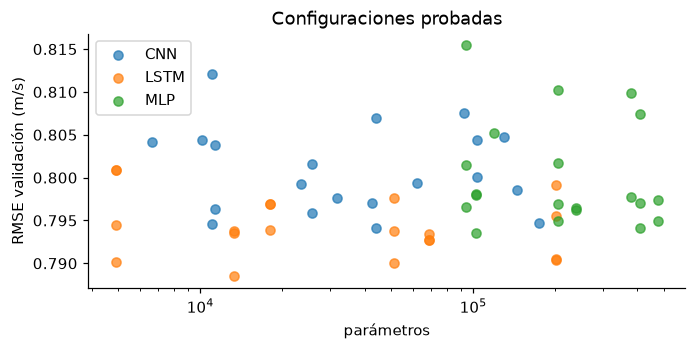

In [4]:
aj = pd.DataFrame(json.load(open("resultados/ajuste.json")))
print(aj.groupby("modelo").agg(configuraciones=("rmse_val", "size"), mejor=("rmse_val", "min"),
                               mediana=("rmse_val", "median"), peor=("rmse_val", "max"),
                               minutos=("segundos", lambda s: s.sum() / 60)).round(4))
print("\nHiperparámetros elegidos:"); print(json.dumps(json.load(open("configs/hiperparametros.json")), indent=1))
fig, ax = plt.subplots(figsize=(7, 3))
for m, g in aj.groupby("modelo"):
    ax.scatter(g.parametros, g.rmse_val, label=m, alpha=.7)
ax.set(xscale="log", xlabel="parámetros", ylabel="RMSE validación (m/s)", title="Configuraciones probadas")
ax.legend(); plt.show()

## Corridas definitivas: curvas de entrenamiento y validación

Líneas continuas: RMSE de validación por época. Líneas punteadas: RMSE de entrenamiento (medido durante la época,
con el dropout activo).

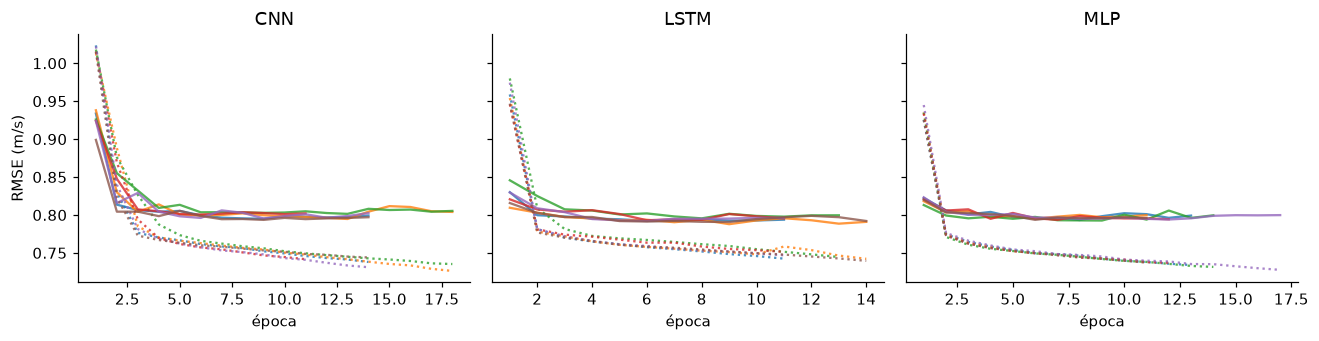

        RMSE_train  RMSE_val  de_val   epocas  segundos  parametros  \
modelo                                                                
CNN         0.7495    0.7968  0.0033  14.8333   31.1345       44129   
LSTM        0.7570    0.7919  0.0025  12.3333   58.3212       13345   
MLP         0.7459    0.7937  0.0008  13.0000    7.1149      102785   

        brecha val − train  
modelo                      
CNN                 0.0472  
LSTM                0.0349  
MLP                 0.0479  


In [5]:
co = pd.DataFrame(json.load(open("resultados/corridas.json")))
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a_, (m, g) in zip(ax, co.groupby("modelo")):
    for i, r in enumerate(g.itertuples()):
        col = f"C{i}"
        a_.plot(range(1, len(r.historia) + 1), r.historia, color=col, alpha=.8)
        a_.plot(range(1, len(r.historia_train) + 1), r.historia_train, color=col, ls=":", alpha=.8)
    a_.set(title=m, xlabel="época"); ax[0].set_ylabel("RMSE (m/s)")
plt.tight_layout(); plt.show()
co["rmse_train_final"] = [h[int(np.argmin(v))] for h, v in zip(co.historia_train, co.historia)]
res = co.groupby("modelo").agg(RMSE_train=("rmse_train_final", "mean"), RMSE_val=("rmse_val", "mean"),
                               de_val=("rmse_val", "std"), epocas=("epocas", "mean"), segundos=("segundos", "mean"),
                               parametros=("parametros", "first"))
res["brecha val − train"] = res.RMSE_val - res.RMSE_train
print(res.round(4))

El error de validación es **mayor** que el de entrenamiento en los tres modelos, pero la brecha no crece con las
épocas: la curva de validación se aplana en pocas épocas y la parada temprana corta antes de que empiece a subir.
Parte de la brecha se explica por el desplazamiento entre años que mostró el EDA (validación cargada hacia
noviembre y diciembre), no solo por sobreajuste. Ningún modelo muestra subajuste evidente: todos bajan mucho del
error de la persistencia (0.963 m/s en validación).

## Sensibilidad: con presión como quinta variable

En el EDA se descartó la presión por su faltante no aleatorio. Para medir cuánto se pierde, se repitió el
entrenamiento con la configuración `configs/datos_con_presion.json` (3 semillas por modelo, solo validación).
Como esa configuración tiene menos estaciones, la comparación es orientativa.

In [6]:
import os
if os.path.exists("resultados/sensibilidad_presion.json"):
    se = pd.DataFrame(json.load(open("resultados/sensibilidad_presion.json")))
    comp = pd.DataFrame({"sin presión (4 variables)": co.groupby("modelo").rmse_val.mean(),
                         "con presión (5 variables)": se.groupby("modelo").rmse_val.mean()})
    print(comp.round(4))

        sin presión (4 variables)  con presión (5 variables)
modelo                                                      
CNN                        0.7968                     0.8151
LSTM                       0.7919                     0.8084
MLP                        0.7937                     0.8095
